# ACME Talent Insights

**Audience:** HR leadership and business stakeholders, and technical reviewers of the data pipeline.

This notebook answers the seven business questions from ACME's problem statement using the **curated Gold layer** of the talent data lake. It does not transform raw data and does not re-implement business rules. Every number comes from the **published Gold version**, which the pipeline built and validated (Bronze → Silver → Gold), through the project's own interfaces (`talent_etl.gold.load_gold_table`).

**How to run it**
1. Set up the project as described in `data/talent-etl/README.md` (`.venv`, `scripts/seed_sources.sh`).
2. Build the lake: `python job.py --step all`.
3. Run this notebook top to bottom. To regenerate it with outputs from the command line:

   `.venv/bin/jupyter execute --inplace notebooks/talent_insights.ipynb`

Configuration comes from the same environment variables as the pipeline (`IS_LOCAL`, `LAKE_BUCKET`, ...). Locally that means LocalStack; in the cloud, S3. No credentials are stored in or printed by this notebook.

**Contents**
- [0. Data freshness and data quality](#0.-Data-freshness-and-data-quality)
- [1. Performance ratings and review history](#1.-Performance-ratings-and-review-history)
- [2. Critical skill gaps](#2.-Critical-skill-gaps)
- [3. High-potential employees ready for promotion](#3.-High-potential-employees-ready-for-promotion)
- [4. Training and development completed](#4.-Training-and-development-completed)
- [5. Attrition risk based on performance trends](#5.-Attrition-risk-based-on-performance-trends)
- [6. Performance vs team and project outcomes](#6.-Performance-vs-team-and-project-outcomes)
- [7. Distribution of skills](#7.-Distribution-of-skills)
- [8. Summary, assumptions and limitations](#8.-Summary,-assumptions-and-limitations)

## The seven business questions and where they are answered

The questions below are quoted verbatim from ACME's problem statement ("Requirements: Business Problem"). That statement was provided to the project team and is not stored in this repository.

| # | Question (verbatim) | Gold tables | Key metrics | Visualization | Coverage |
|---|---|---|---|---|---|
| 1 | *What are the performance ratings and review history for each employee?* | `performance_history`, `employee_performance`, `dim_employee` | Latest valid rating, rating trend, full review history per employee | Bars: latest-rating distribution and rating trend | Answered. Only two review periods exist, so a trend is a single change. |
| 2 | *Which employees have critical skill gaps in key competencies?* | `employee_skill_gaps`, `competency_gap_summary` | Critical gaps (approved definition), employees with critical gaps, critical-gap rate per competency | Horizontal bars: competencies with the highest critical-gap rate | Answered. The source does not define which competencies are "key", so all 40 are ranked. |
| 3 | *Who are the high-potential employees ready for promotion?* | `promotion_pipeline` | Employees meeting the promotion-ready rule, and how each criterion narrows the group | Horizontal bars: how the criteria narrow the group | Answered under a **proposed** rule (A19), not an HR-approved one |
| 4 | *What training and development activities have been completed by each employee?* | `employee_learning` | Distinct courses completed, certifications, activity counts | Bars: employees by number of courses completed | Answered. There is no course-to-competency mapping and no funnel rates (A23). |
| 5 | *Which employees are at risk of attrition based on performance trends?* | `attrition_risk`, `employee_performance` | Declining performance trend, heuristic risk band | Bars: risk bands, plus a table of trend × band | Partly answered. The score is a **heuristic** (A20); no data on actual leavers exists to validate it. |
| 6 | *How does employee performance correlate with team and project outcomes?* | `team_performance` | Team average rating vs project outcome score (r, n) | Scatter: team rating vs project outcome | Partly answered. Projects link to teams only, and only 27 of 100 teams have projects. |
| 7 | *What is the distribution of skills across the organization?* | `skill_distribution`, `competency_gap_summary` | Proficiency by department × competency category, and level mix | Heatmap: average proficiency by department × category | Answered, from a sample of 2 assessed competencies per employee |

In [1]:
from pathlib import Path
import math
import sys

# Locate the project package from wherever the notebook is opened (no hardcoded data paths).
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "talent_etl").is_dir())
sys.path.insert(0, str(PROJECT))

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from talent_etl import definitions, dq_report
from talent_etl.config import Settings
from talent_etl.gold import load_gold_table, read_current_gold
from talent_etl.io_s3 import S3Client
from talent_etl.retry import RetryPolicy
from talent_etl.silver import read_current

settings = Settings.from_env()          # IS_LOCAL, LAKE_BUCKET, ... from the environment (secrets never printed)
s3 = S3Client(settings.s3, RetryPolicy.from_config(settings.retry))
BUCKET = settings.s3.lake_bucket
gold_pointer = read_current_gold(s3, BUCKET)
silver_pointer = read_current(s3, BUCKET)
assert gold_pointer is not None, "No published Gold version: run `python job.py --step all` first."

_cache = {}
def gold(name):
    # One table of the published Gold version, as pandas (read once per session).
    if name not in _cache:
        _cache[name] = load_gold_table(s3, BUCKET, name).to_pandas()
    return _cache[name].copy()

employees = gold("dim_employee")[["employee_id", "first_name", "last_name", "department", "team_name", "job_level", "hire_date"]]
employees["employee"] = employees["first_name"] + " " + employees["last_name"]
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
print("Notebook ready.")

Notebook ready.


In [2]:
# Chart style: light surface, recessive hairline grid, one series colour, sequential blue for magnitude.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = "#2a78d6"                                     # single-series colour
SEQUENTIAL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.axisbelow": True,
    "font.family": "sans-serif", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "figure.dpi": 110,
})

def bars(ax, labels, values, title, xlabel=None, ylabel=None, horizontal=False, fmt="{:,.0f}"):
    # Single-series bar chart with value labels at the bar ends.
    positions = range(len(values))
    drawn = (ax.barh(positions, values, color=SERIES, height=0.6) if horizontal
             else ax.bar(positions, values, color=SERIES, width=0.6))
    if horizontal:
        ax.set_yticks(list(positions), labels); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    else:
        ax.set_xticks(list(positions), labels); ax.grid(axis="x", visible=False)
    ax.bar_label(drawn, labels=[fmt.format(v) for v in values], padding=3, color=INK_2, fontsize=9)
    ax.set_title(title)
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    ax.margins(x=0.12 if horizontal else 0.02, y=0.02 if horizontal else 0.12)

def pct(x):
    return f"{x:.1%}"

## 0. Data freshness and data quality

Every answer below describes the Gold version shown here. **"As of" is the date of the source snapshot** the pipeline processed. All time-relative measures, such as "the last 12 months" of learning, are computed relative to it, not to today's date.

In [3]:
freshness = pd.DataFrame({"value": {
    "Environment": "local (LocalStack)" if settings.is_local else "cloud (AWS)",
    "Lake bucket": BUCKET,
    "Data as of (source snapshot)": gold_pointer.as_of,
    "Gold version (run id)": gold_pointer.run_id,
    "Gold published at (UTC)": gold_pointer.published_at[:19],
    "Built from Silver version": gold_pointer.silver_run_id,
}})
display(freshness)

,value
Environment,cloud (AWS)
Lake bucket,coding-workshop-cda06d6a-talent-lake-cda06d6a
Data as of (source snapshot),2026-10-15
Gold version (run id),20261015T064714Z-e66efa1f
Gold published at (UTC),2026-10-15T06:49:04
Built from Silver version,20261015T064714Z-e66efa1f


**How trustworthy is the input?** Silver validated every source record against its schema contract and data-quality rules before Gold was built. The table below shows, per source entity, how many records were read, accepted, quarantined (rejected, with a recorded reason) or dropped as duplicates.

In [4]:
silver_manifest = dq_report.published_manifest(s3, BUCKET)
quality = dq_report.entity_quality_table(silver_manifest)[
    ["read", "accepted", "accepted_with_warnings", "quarantined", "deduplicated", "quarantine_rate"]]
display(quality.assign(quarantine_rate=quality["quarantine_rate"].map(pct)))

,read,accepted,accepted_with_warnings,quarantined,deduplicated,quarantine_rate
entity,,,,,,
teams,100,100,0,0,0,0.0%
competencies,40,40,0,0,0,0.0%
employees,2000,2000,0,0,0,0.0%
projects,33,33,0,0,0,0.0%
performance_reviews,4000,4000,666,0,0,0.0%
competency_assessments,4000,4000,234,0,0,0.0%
talent_review,2000,2000,270,0,0,0.0%
learning_activity,29868,29574,5185,142,152,0.5%


**Learning-history sequence metrics (informational, not row warnings).** These show how often a course completion has no earlier enrollment, and how often a certification has no earlier completion. Both rates sit inside the range expected if event types were recorded in **random order**. The learning events therefore carry no reliable sequence, which is why this notebook reports **no funnel or conversion rates** (decision A23).

In [5]:
display(dq_report.history_metrics_table(silver_manifest)[
    ["metric", "events", "flagged", "rate", "random_baseline_rate", "vs_random"]])

,metric,events,flagged,rate,random_baseline_rate,vs_random
rule_id,,,,,,
BUS-010,completion_without_enrollment,3490,3406,0.975931,0.974898,consistent with random order
BUS-011,certification_without_completion,1764,1731,0.981293,0.980014,consistent with random order


**Gold validation.** Before publishing, every Gold table passed its checks: schema, grain (a unique key), allowed values and ranges, and reconciliation with Silver (row counts and totals). The table below reads those results from the run that built each table.

In [6]:
checks = dq_report.gold_checks_table(s3, BUCKET)
display(checks[["rows", "built_by_run", "checks", "passed"]])
assert (checks["checks"] == checks["passed"]).all(), "A Gold check failed: do not use these results."
print(f"All {int(checks['checks'].sum())} Gold checks passed across {len(checks)} tables.")

,rows,built_by_run,checks,passed
table,,,,
dim_employee,2000,20261015T064714Z-e66efa1f,4,4
performance_history,4000,20261015T064714Z-e66efa1f,7,7
employee_performance,2000,20261015T064714Z-e66efa1f,9,9
employee_skill_gaps,4000,20261015T064714Z-e66efa1f,7,7
competency_gap_summary,40,20261015T064714Z-e66efa1f,6,6
skill_distribution,1595,20261015T064714Z-e66efa1f,6,6
employee_learning,2000,20261015T064714Z-e66efa1f,7,7
promotion_pipeline,2000,20261015T064714Z-e66efa1f,5,5
attrition_risk,2000,20261015T064714Z-e66efa1f,9,9


All 69 Gold checks passed across 10 tables.


## 1. Performance ratings and review history

> **Question 1 (verbatim):** *What are the performance ratings and review history for each employee?*

**Business objective:** give managers and HR one reliable view of every employee's ratings over time. It also identifies each employee's latest rating and whether it is improving or declining.

**Data used:**
- `performance_history`: one row per employee and review period.
- `employee_performance`: one row per employee, with the latest valid rating and trend.

**Key terms:**
- **Valid review:** a review for a period that ended on or after the employee's hire date. A review for a period that ended before the person joined cannot describe their work at ACME, so it is kept in the history but labelled and excluded from ratings (A7).
- **Trend:** the change between the latest valid rating and the valid rating for the immediately preceding half-year.

Employees: 2,000 | with at least one valid review: 1,730 | reviews in history: 4,000 (of which pre-hire, excluded from ratings: 666)


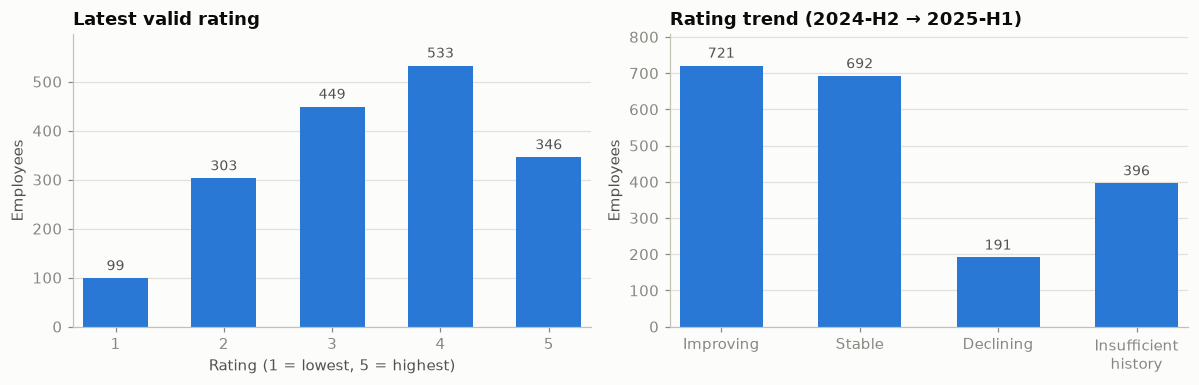

,employees,share
latest valid rating,,
1,99,5.7%
2,303,17.5%
3,449,26.0%
4,533,30.8%
5,346,20.0%


,employees,share
rating trend,,
improving,721,36.0%
stable,692,34.6%
declining,191,9.6%
insufficient_history,396,19.8%


In [7]:
history = gold("performance_history")
perf = gold("employee_performance")
rated = perf.dropna(subset=["latest_valid_rating"])
print(f"Employees: {len(perf):,} | with at least one valid review: {len(rated):,} | "
      f"reviews in history: {len(history):,} (of which pre-hire, excluded from ratings: {int(history['is_pre_hire'].sum()):,})")

rating_dist = rated["latest_valid_rating"].astype(int).value_counts().sort_index()
trend_order = ["improving", "stable", "declining", "insufficient_history"]
trend_dist = perf["rating_trend"].value_counts().reindex(trend_order)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
bars(ax1, [f"{r}" for r in rating_dist.index], rating_dist.values, "Latest valid rating", "Rating (1 = lowest, 5 = highest)", "Employees")
bars(ax2, ["Improving", "Stable", "Declining", "Insufficient\nhistory"], trend_dist.values, "Rating trend (2024-H2 → 2025-H1)", None, "Employees")
fig.tight_layout(); plt.show()

display(pd.DataFrame({"employees": rating_dist, "share": (rating_dist / rating_dist.sum()).map(pct)}).rename_axis("latest valid rating"))
display(pd.DataFrame({"employees": trend_dist, "share": (trend_dist / len(perf)).map(pct)}).rename_axis("rating trend"))

**Review history for each employee.** The full history is in `performance_history`. The helper below shows it for any employee. Three typical cases follow: an employee with a complete history, a mid-period hire whose earlier review is labelled pre-hire, and a recent hire whose reviews are all pre-hire.

In [8]:
def review_history(employee_id):
    rows = history[history["employee_id"] == employee_id].merge(employees, on="employee_id")
    return rows[["employee", "hire_date", "review_period", "rating", "is_valid", "previous_valid_rating", "rating_change"]]

complete = perf[(perf["rating_trend"] != "insufficient_history") & (perf["pre_hire_review_count"] == 0)]["employee_id"].iloc[0]
mid_period = perf[(perf["valid_review_count"] == 1) & (perf["pre_hire_review_count"] == 1)]["employee_id"].iloc[0]
all_pre_hire = perf[perf["valid_review_count"] == 0]["employee_id"].iloc[0]
for employee_id in (complete, mid_period, all_pre_hire):
    display(review_history(employee_id))

,employee,hire_date,review_period,rating,is_valid,previous_valid_rating,rating_change
0,Heather Davis,2024-04-06,2024-H2,3,True,NaN,NaN
1,Heather Davis,2024-04-06,2025-H1,4,True,3.0,1.0


,employee,hire_date,review_period,rating,is_valid,previous_valid_rating,rating_change
0,Emily Clark,2025-01-30,2024-H2,3,False,NaN,NaN
1,Emily Clark,2025-01-30,2025-H1,3,True,NaN,NaN


,employee,hire_date,review_period,rating,is_valid,previous_valid_rating,rating_change
0,Linda Murray,2025-11-01,2024-H2,2,False,NaN,NaN
1,Linda Murray,2025-11-01,2025-H1,3,False,NaN,NaN


**Interpretation**
- **Ratings are centred on 3–4.** Of the 1,730 employees with a valid review, 879 have a latest rating of 4 or 5 (high performers) and 402 have 1 or 2 (low performers).
- **More employees are improving than declining.** Of the 1,604 employees with a measurable trend, 721 improved, 692 were stable and 191 declined.
- **396 employees have no trend.** 270 have no valid review at all, because every review predates their hire, and 126 have only one.
- **For managers:** the per-employee history above is the record to use in performance conversations. Pre-hire reviews are visible but clearly marked.

**Assumptions and limitations**
- **Only two review periods exist** (2024-H2 and 2025-H1), so a "trend" is a single change and should not be read as a long-term trajectory.
- **The 666 reviews dated before the employee's hire date** look like a data-generation or source-system issue. They are excluded from ratings (proposed A7) and should be raised with the data owner.

## 2. Critical skill gaps

> **Question 2 (verbatim):** *Which employees have critical skill gaps in key competencies?*

**Business objective:** find the people and the competencies where proficiency falls furthest below what the role requires, so that development effort can be targeted.

**Data used:**
- `employee_skill_gaps`: the latest assessment per employee and competency.
- `competency_gap_summary`: one row per competency.

**Definition (approved, A1):** a gap is **critical** when the employee is missing **at least half of the required level**. In other words, (required − actual) ÷ required ≥ ½. For example:
- required 2, actual 1 → critical
- required 4, actual 2 → critical
- required 3, actual 2 → not critical

This makes the threshold fair at every required level.

Assessments (latest per employee and competency): 4,000 | critical gaps: 682 (17.1%) | employees with at least one critical gap: 633 of 2,000


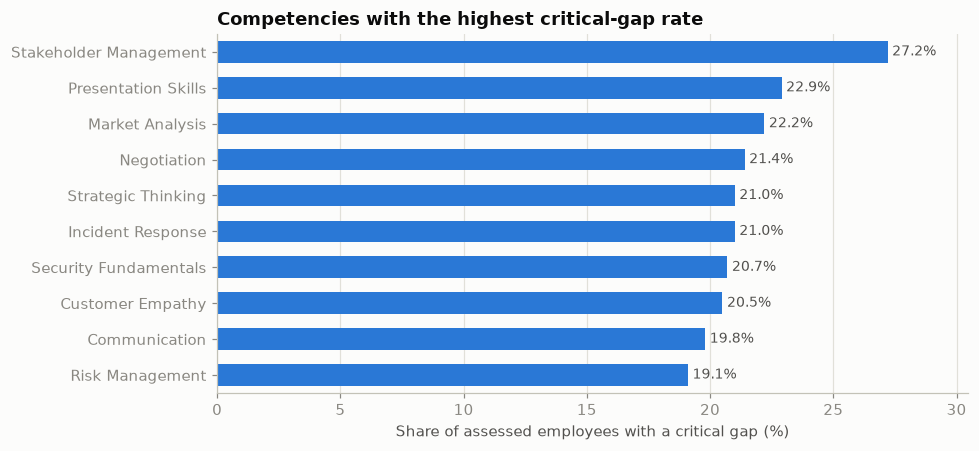

,competency_category,employees_assessed,critical_gap_count,critical_gap_rate
competency_name,,,,
Stakeholder Management,Domain,92,25,27.2%
Presentation Skills,Domain,105,24,22.9%
Market Analysis,Domain,99,22,22.2%
Negotiation,Domain,103,22,21.4%
Strategic Thinking,Leadership,119,25,21.0%
Incident Response,Technical,105,22,21.0%
Security Fundamentals,Technical,92,19,20.7%
Customer Empathy,Domain,88,18,20.5%
Communication,Domain,91,18,19.8%


,assessments,critical_gaps,critical_gap_rate
competency_category,,,
Domain,2069,363,17.5%
Leadership,638,104,16.3%
Technical,1293,215,16.6%


In [9]:
gaps = gold("employee_skill_gaps")
summary = gold("competency_gap_summary")
critical = gaps[gaps["is_critical_gap"]]
per_employee = critical.groupby("employee_id").agg(critical_gaps=("competency_id", "count"),
                                                    competencies=("competency_name", lambda s: ", ".join(sorted(s))))
print(f"Assessments (latest per employee and competency): {len(gaps):,} | critical gaps: {len(critical):,} "
      f"({len(critical) / len(gaps):.1%}) | employees with at least one critical gap: {len(per_employee):,} of {gaps['employee_id'].nunique():,}")

top = summary.sort_values(["critical_gap_rate", "critical_gap_count"], ascending=False).head(10)
fig, ax = plt.subplots(figsize=(9, 4.2))
bars(ax, top["competency_name"].tolist(), (top["critical_gap_rate"] * 100).round(1).tolist(),
     "Competencies with the highest critical-gap rate", "Share of assessed employees with a critical gap (%)",
     horizontal=True, fmt="{:.1f}%")
fig.tight_layout(); plt.show()

display(top[["competency_name", "competency_category", "employees_assessed", "critical_gap_count", "critical_gap_rate"]]
        .assign(critical_gap_rate=top["critical_gap_rate"].map(pct)).set_index("competency_name"))
by_category = gaps.groupby("competency_category").agg(assessments=("is_critical_gap", "size"),
                                                      critical_gaps=("is_critical_gap", "sum"))
by_category["critical_gap_rate"] = by_category["critical_gaps"] / by_category["assessments"]
display(by_category.assign(critical_gap_rate=by_category["critical_gap_rate"].map(pct)))

**Which employees?** The list below shows the employees with critical gaps: those with the most critical gaps first, then by name. The full list is in `employee_skill_gaps` (`is_critical_gap = true`).

In [10]:
named = per_employee.join(employees.set_index("employee_id")[["employee", "department", "job_level"]])
display(named.sort_values(["critical_gaps", "employee"], ascending=[False, True])
        [["employee", "department", "job_level", "critical_gaps", "competencies"]].head(15))
print(f"Employees with 2 critical gaps: {int((per_employee['critical_gaps'] >= 2).sum())} | with exactly 1: {int((per_employee['critical_gaps'] == 1).sum())}")

,employee,department,job_level,critical_gaps,competencies
employee_id,,,,,
1757,Adam Fields,Finance,IC3,2,"Incident Response, Systems Design"
819,Alexis Taylor,Data & Analytics,IC1,2,"API Design, Negotiation"
1225,Amy Tucker,Marketing,IC1,2,"Market Analysis, Project Management"
1853,Ashley Miller,Human Resources,IC1,2,"Customer Empathy, Presentation Skills"
1847,Autumn Chambers,Human Resources,Manager,2,"Onboarding & Enablement, Security Fundamentals"
1248,Barbara Brown,Customer Support,IC1,2,"Coaching & Mentoring, Negotiation"
1936,Brandon Morgan,Data & Analytics,IC3,2,"Communication, Stakeholder Management"
505,Carrie Duncan,Human Resources,IC3,2,"Technical Writing, Test Automation"
1277,Christian Macias,Finance,Senior Manager,2,"Accessibility, Incident Response"


Employees with 2 critical gaps: 49 | with exactly 1: 584


**Interpretation**
- **682 assessments (17.05%) show a critical gap, held by 633 of the 2,000 employees.** 584 have one critical gap and 49 have two (each employee was assessed on two competencies).
- **Rates differ across competencies**, from 10.4% to 27.2%. Stakeholder Management is highest, followed by Presentation Skills and Market Analysis. The top of the chart is a reasonable shortlist for organisation-wide training programmes.
- **The three categories have similar rates** (Domain 17.5%, Technical 16.6%, Leadership 16.3%). No category stands out as systematically weaker.
- **The employee list is the actionable output for managers.** It names who needs a development plan, and in which competency.

**Assumptions and limitations**
- **"Key competencies" is not defined in any source.** All 40 competencies are treated alike and ranked by critical-gap rate. If HR names its key competencies, the same tables can be filtered to them.
- **Employees are not assessed on every competency.** Each was assessed on 2 of the 40 (about 100 people per competency), so a competency's rate is a sample estimate, and an employee without an assessment may still have a gap.
- **234 assessments are dated before the employee's hire date.** They are included, on the assumption that they measure real skill (proposed A5).

## 3. High-potential employees ready for promotion

> **Question 3 (verbatim):** *Who are the high-potential employees ready for promotion?*

**Business objective:** give HR a shortlist of promotion candidates, with the evidence behind each one.

**Data used:** `promotion_pipeline`, with one row per employee with a talent review.

**Rule (PROPOSED, A19; not yet approved by HR):** an employee is promotion-ready when all three hold:
- potential rating is **High**
- promotion readiness is **Ready Now**
- latest **valid** performance rating is **4 or higher**

Critical skill gaps are shown alongside, but they do not exclude anyone.

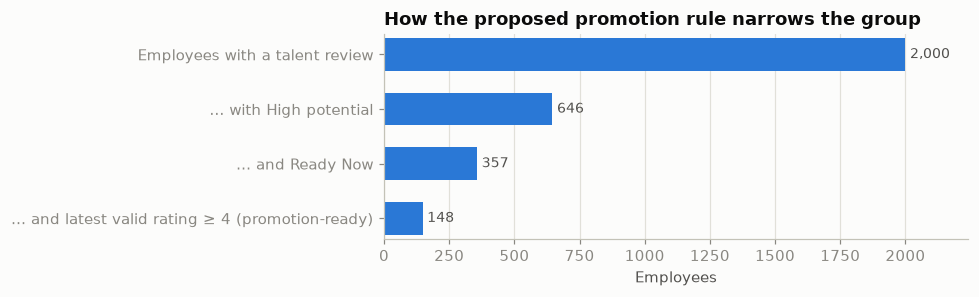

Promotion-ready: 148 | High & Ready Now but no valid rating (cannot qualify): 45 | ready with at least one critical skill gap: 61


department,Human Resources,Data & Analytics,Sales,Customer Support,Product,Engineering,Operations,Design,Marketing,Finance
promotion-ready,23,20,20,17,17,13,13,12,7,6


,employee,department,job_level,latest_valid_rating,rating_trend,critical_gap_count,courses_completed
0,Alejandra Perkins,Design,Senior IC,5.0,insufficient_history,0,0
1,Barbara Lozano,Product,IC1,5.0,improving,0,2
2,Cameron Williams,Data & Analytics,Manager,5.0,improving,0,2
3,Christine Moore,Engineering,Senior IC,5.0,improving,0,4
4,Cynthia Tran,Product,IC3,5.0,improving,0,5
5,Dakota Mendez,Engineering,Director,5.0,improving,0,2
6,Daniel Mcintyre,Marketing,Director,5.0,improving,0,3
7,Daniel Osborne,Customer Support,Manager,5.0,improving,0,1
8,Daniel Scott,Human Resources,IC1,5.0,improving,0,3
9,Heather Bowman,Engineering,IC2,5.0,improving,0,1


In [11]:
pipe = gold("promotion_pipeline")
high = pipe["potential_rating"] == definitions.PROMOTION_POTENTIAL
ready_now = high & (pipe["promotion_readiness"] == definitions.PROMOTION_READINESS)
stages = pd.Series({
    "Employees with a talent review": len(pipe),
    "… with High potential": int(high.sum()),
    "… and Ready Now": int(ready_now.sum()),
    f"… and latest valid rating ≥ {definitions.PROMOTION_MIN_RATING} (promotion-ready)": int(pipe["is_promotion_ready"].sum()),
})
fig, ax = plt.subplots(figsize=(9, 2.8))
bars(ax, stages.index.tolist(), stages.values, "How the proposed promotion rule narrows the group", "Employees", horizontal=True)
fig.tight_layout(); plt.show()

ready = pipe[pipe["is_promotion_ready"]].merge(employees[["employee_id", "employee"]], on="employee_id")
no_rating = int((ready_now & pipe["latest_valid_rating"].isna()).sum())
print(f"Promotion-ready: {len(ready)} | High & Ready Now but no valid rating (cannot qualify): {no_rating} | "
      f"ready with at least one critical skill gap: {int((ready['critical_gap_count'] > 0).sum())}")
display(ready.groupby("department").size().rename("promotion-ready").sort_values(ascending=False).to_frame().T)
display(ready.sort_values(["latest_valid_rating", "critical_gap_count", "employee"], ascending=[False, True, True])
        [["employee", "department", "job_level", "latest_valid_rating", "rating_trend", "critical_gap_count", "courses_completed"]]
        .head(15).reset_index(drop=True))

**Interpretation**
- **148 employees meet the proposed rule**, out of 357 whom HR rated High potential and Ready Now.
- **209 of those 357 fail the performance criterion.** 164 have a latest valid rating below 4.
- **45 have no valid rating at all**, because all their reviews predate their hire, so their performance cannot be confirmed.
- **61 of the 148 have at least one critical skill gap.** HR may want to pair these promotions with a targeted development plan.
- **The list above is ordered for review:** highest rating first, then fewest critical gaps.

**Assumptions and limitations**
- **This is a rule-based shortlist, not an approved HR policy (A19).** The thresholds can be changed in `definitions.py` and the pipeline re-run.
- **270 talent reviews are dated before the employee's hire date.** They are included and labelled `talent_review_pre_hire` (proposed A6). No pre-hire talent review produces a promotion-ready employee, because those employees have no valid rating.

## 4. Training and development completed

> **Question 4 (verbatim):** *What training and development activities have been completed by each employee?*

**Business objective:** show each employee's completed courses and certifications, and the overall level of learning activity.

**Data used:** `employee_learning`, with one row per employee.

**Definitions:**
- **Course completed (approved, A13):** an explicit `course_completed` event counts, even if no enrollment was recorded. Repeated completions of the same course count once.
- **Certifications** are counted the same way.
- **Pre-hire activity** is excluded and counted separately (proposed A4).

,value
Distinct course completions,"2,824"
Certifications earned,"1,465"
Employees with at least one completed course,"1,458"
Employees with at least one certification,996
Learning events counted,"24,413"
Pre-hire events excluded,"5,161"
Employees with no learning in the last 12 months,56


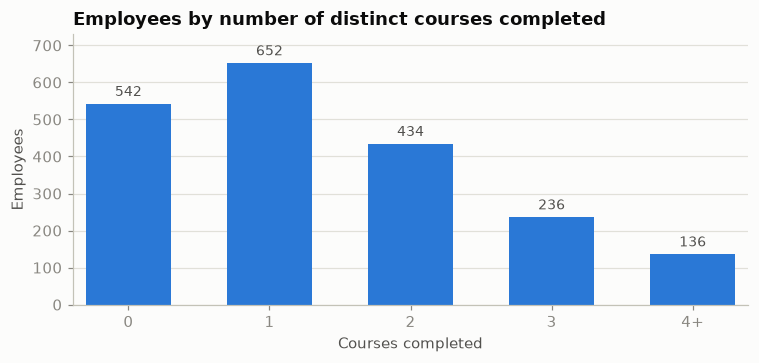

In [12]:
learning = gold("employee_learning")
totals = pd.Series({
    "Distinct course completions": int(learning["courses_completed"].sum()),
    "Certifications earned": int(learning["certifications_earned"].sum()),
    "Employees with at least one completed course": int((learning["courses_completed"] > 0).sum()),
    "Employees with at least one certification": int((learning["certifications_earned"] > 0).sum()),
    "Learning events counted": int(learning["events_counted"].sum()),
    "Pre-hire events excluded": int(learning["pre_hire_events_excluded"].sum()),
    "Employees with no learning in the last 12 months": int((~learning["is_learning_active_12m"]).sum()),
}, name="value")
display(totals.map("{:,}".format).to_frame())

completed = learning["courses_completed"].clip(upper=4).astype(int).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.4))
bars(ax, ["0", "1", "2", "3", "4+"][: len(completed)], completed.values, "Employees by number of distinct courses completed",
     "Courses completed", "Employees")
fig.tight_layout(); plt.show()

**What each employee completed.** Here are the most active learners, followed by a helper that lists any employee's record. The complete per-employee table is `employee_learning`.

In [13]:
per_person = learning.merge(employees[["employee_id", "employee", "department"]], on="employee_id")
cols = ["employee", "department", "courses_completed", "certifications_earned", "courses_enrolled",
        "quiz_attempts", "quiz_passes", "avg_quiz_score", "last_activity_date"]
display(per_person.sort_values(["courses_completed", "certifications_earned", "employee"], ascending=[False, False, True])[cols]
        .head(10).reset_index(drop=True).round({"avg_quiz_score": 1}))

def learning_record(employee_id):
    return per_person[per_person["employee_id"] == employee_id][cols]
display(learning_record(complete))

,employee,department,courses_completed,certifications_earned,courses_enrolled,quiz_attempts,quiz_passes,avg_quiz_score,last_activity_date
0,Kristen Johnson,Data & Analytics,7,0,3,1,2,69.0,2026-08-03
1,Mark Castillo,Product,7,0,4,2,0,31.5,2026-08-14
2,Joshua James,Finance,6,2,2,1,1,56.5,2026-03-20
3,Jane Dalton,Data & Analytics,6,1,4,4,0,44.0,2026-05-15
4,Arthur Flores,Operations,6,0,2,0,1,91.0,2026-06-16
5,Carol Scott,Finance,6,0,3,2,1,66.7,2026-07-22
6,Jordan Jefferson,Customer Support,6,0,3,2,3,74.6,2026-05-11
7,Joseph Delgado,Sales,6,0,0,3,4,62.1,2026-07-01
8,Stephanie Barker,Human Resources,6,0,3,2,0,43.0,2026-07-09
9,Alexis Taylor,Data & Analytics,5,3,1,2,2,70.8,2026-07-08


,employee,department,courses_completed,certifications_earned,courses_enrolled,quiz_attempts,quiz_passes,avg_quiz_score,last_activity_date
0,Heather Davis,Sales,2,0,1,3,3,67.833333,2026-06-23


**Interpretation**
- **1,458 of 2,000 employees completed at least one course.** That makes 2,824 distinct completions and 1,465 certifications. 542 employees have completed none.
- **Learning is broad but shallow.** Of the employees who completed anything, 74% completed one or two courses (652 + 434).
- **Nearly everyone has been active recently.** Only 56 employees recorded no learning activity in the 12 months before the as-of date.

**Assumptions and limitations**
- **No funnel or conversion rates are shown** (completion rate, quiz pass rate). The data-quality section showed the learning events are not recorded in a reliable sequence. The top-learners table shows the effect: employees with more quiz passes than quiz attempts. Counts and average scores are reliable; ratios between funnel steps are not (A23).
- **Training is not linked to skill gaps.** No source maps the 42 course titles to the 40 competencies, and an invented mapping would be misleading.
- **Pre-hire learning events are excluded** from these totals (5,161 events, proposed A4). They are kept in Silver and can be included if HR prefers.

## 5. Attrition risk based on performance trends

> **Question 5 (verbatim):** *Which employees are at risk of attrition based on performance trends?*

**Business objective:** flag employees who may be at risk of leaving, so that managers can intervene early. The question asks specifically about performance trends.

**Data used:**
- `attrition_risk`, with one row per employee.
- `employee_performance`, for the trend.

**Method (HEURISTIC, A20; not a validated prediction model):** each employee gets points from separate, explainable signals:

| Signal | Points |
|---|---|
| HR's own attrition-risk rating | High = 2, Medium = 1 |
| Declining performance trend | 1 |
| Latest valid rating of 2 or lower | 1 |
| No learning activity in the last 12 months | 1 |

**Bands:** 3+ points = High risk, 2 = Medium, 0–1 = Low.

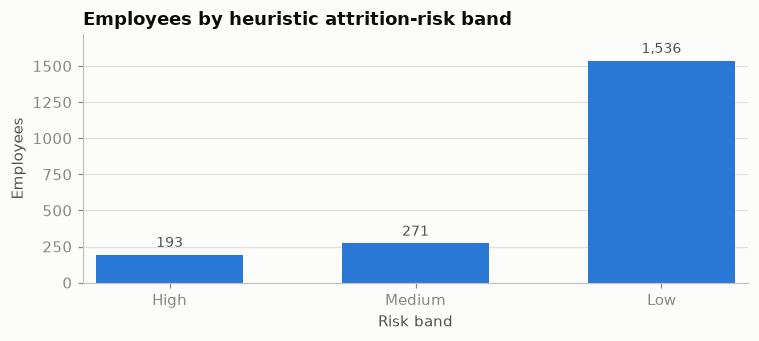

risk band,High,Medium,Low,Total
rating trend,,,,
improving,0,69,652,721
stable,21,108,563,692
declining,161,26,4,191
insufficient_history,11,68,317,396
Total,193,271,1536,2000


Employees with a declining trend: 191 | of which High band: 161 | also rated High risk by HR: 116


In [14]:
risk = gold("attrition_risk")
band_order = ["High", "Medium", "Low"]
bands = risk["risk_band"].value_counts().reindex(band_order)
fig, ax = plt.subplots(figsize=(7, 3.2))
bars(ax, band_order, bands.values, "Employees by heuristic attrition-risk band", "Risk band", "Employees")
fig.tight_layout(); plt.show()

display(pd.crosstab(risk["rating_trend"], risk["risk_band"], margins=True, margins_name="Total")
        .reindex(index=trend_order + ["Total"], columns=band_order + ["Total"]).rename_axis(index="rating trend", columns="risk band"))

declining = risk[risk["is_rating_declining"]]
print(f"Employees with a declining trend: {len(declining)} | of which High band: {int((declining['risk_band'] == 'High').sum())} | "
      f"also rated High risk by HR: {int((declining['hr_attrition_risk'] == 'High').sum())}")

**Who is at risk?** These are the employees in the High band, highest points first, with the signals that put them there. The full list is in `attrition_risk`.

In [15]:
signals = risk.merge(employees[["employee_id", "employee", "department", "job_level"]], on="employee_id")
display(signals[signals["risk_band"] == "High"].sort_values(["risk_points", "employee"], ascending=[False, True])
        [["employee", "department", "job_level", "risk_points", "hr_attrition_risk", "rating_trend",
          "latest_valid_rating", "is_low_latest_rating", "is_learning_inactive_12m"]].head(15).reset_index(drop=True))

,employee,department,job_level,risk_points,hr_attrition_risk,rating_trend,latest_valid_rating,is_low_latest_rating,is_learning_inactive_12m
0,Anne Long,Operations,IC1,5,High,declining,2.0,True,True
1,Joseph Ford,Design,IC3,5,High,declining,1.0,True,True
2,Abigail Butler,Data & Analytics,Director,4,High,declining,1.0,True,False
3,Adam Fields,Finance,IC3,4,High,declining,1.0,True,False
4,Alexander Patton,Sales,Manager,4,High,declining,1.0,True,False
5,Alexandra Lee,Operations,IC3,4,High,declining,1.0,True,False
6,Alexandria Everett,Customer Support,Director,4,High,declining,2.0,True,False
7,Amanda Crawford,Customer Support,Manager,4,High,declining,1.0,True,False
8,Amanda Jackson,Sales,IC1,4,High,declining,1.0,True,False
9,Amy Sanchez,Data & Analytics,IC3,4,High,stable,2.0,True,True


**Interpretation**
- **191 employees have a declining performance trend.** That is the direct answer to "based on performance trends". 116 of them are also rated High risk by HR, so the two sources point the same way.
- **Combining the signals puts 193 employees in the High band** and 271 in Medium. 161 of the 193 High-band employees have a declining trend, so the band is driven mainly by performance, as the question asks.
- **The list is a starting point for conversations, not a verdict.** Every flag can be traced to the signals shown.

**Assumptions and limitations**
- **This is a heuristic, not a prediction model.** There is no data on who actually left ACME, so the score cannot be validated or calibrated. Its weights (A20) are a proposal.
- **The trend is a single change** between two half-years, and 396 employees have no trend.
- **270 HR attrition ratings come from talent reviews dated before the employee's hire date** (proposed A6). They are included as given.

## 6. Performance vs team and project outcomes

> **Question 6 (verbatim):** *How does employee performance correlate with team and project outcomes?*

**Business objective:** find out whether teams with stronger individual performance also deliver better project outcomes.

**Data used:** `team_performance`, with one row per team: the average latest valid rating of its members, the share of high performers, and the outcomes of the team's projects.

Teams: 100 | teams with projects: 27 | Pearson r = 0.136 | Spearman rho = 0.132 | t = 0.68 (not significant at 5% for n = 27)


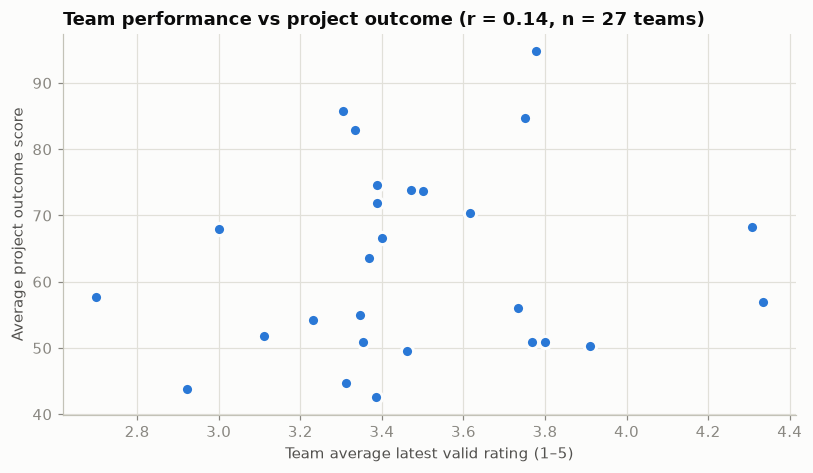

,teams,avg_team_rating,avg_outcome_score
delivery,,,
all on time,15,3.58,69.02
mixed,5,3.53,60.01
none on time,7,3.22,51.31


In [16]:
teams = gold("team_performance")
with_projects = teams[teams["has_projects"]].dropna(subset=["avg_latest_valid_rating", "avg_project_outcome_score"])
n = len(with_projects)
r = with_projects["avg_latest_valid_rating"].corr(with_projects["avg_project_outcome_score"])
rho = with_projects["avg_latest_valid_rating"].rank().corr(with_projects["avg_project_outcome_score"].rank())  # Spearman = Pearson on ranks
t = r * math.sqrt((n - 2) / (1 - r ** 2))
print(f"Teams: {len(teams)} | teams with projects: {n} | Pearson r = {r:.3f} | Spearman rho = {rho:.3f} | t = {t:.2f} "
      f"({'not ' if abs(t) < 2.06 else ''}significant at 5% for n = {n})")

fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.scatter(with_projects["avg_latest_valid_rating"], with_projects["avg_project_outcome_score"], s=64, color=SERIES,
           edgecolor=SURFACE, linewidth=2, zorder=3)
ax.set_title(f"Team performance vs project outcome (r = {r:.2f}, n = {n} teams)")
ax.set_xlabel("Team average latest valid rating (1–5)")
ax.set_ylabel("Average project outcome score")
fig.tight_layout(); plt.show()

on_time = with_projects.assign(delivery=with_projects["on_time_project_share"].map(
    lambda s: "all on time" if s == 1 else ("none on time" if s == 0 else "mixed")))
display(on_time.groupby("delivery").agg(teams=("team_id", "count"), avg_team_rating=("avg_latest_valid_rating", "mean"),
                                        avg_outcome_score=("avg_project_outcome_score", "mean")).round(2))

**Performance by department.** This is context for the team view: the average latest valid rating and the share of high performers per department.

In [17]:
dept = perf.merge(employees[["employee_id", "department"]], on="employee_id").dropna(subset=["latest_valid_rating"])
display(dept.groupby("department").agg(rated_employees=("employee_id", "count"), avg_latest_rating=("latest_valid_rating", "mean"),
                                       high_performer_share=("is_high_performer", "mean"))
        .sort_values("avg_latest_rating", ascending=False)
        .assign(avg_latest_rating=lambda d: d["avg_latest_rating"].round(2), high_performer_share=lambda d: d["high_performer_share"].map(pct)))

,rated_employees,avg_latest_rating,high_performer_share
department,,,
Customer Support,175,3.54,56.6%
Human Resources,276,3.49,54.0%
Product,186,3.45,50.5%
Sales,205,3.43,52.7%
Finance,84,3.43,52.4%
Engineering,131,3.40,44.3%
Data & Analytics,234,3.38,50.0%
Design,166,3.35,46.4%
Operations,165,3.33,50.3%


**Interpretation**
- **The relationship is weak and not statistically significant** (r ≈ 0.14 across 27 teams). On this data, teams with higher-rated members do **not** clearly deliver better project outcomes.
- **Delivery status points the same way, but on very few teams.**
  - The 15 teams whose projects were all on time average 3.58, against 3.22 for the 7 teams with none on time.
  - Their outcome scores are 69 against 51.
  - With groups this small, it is a hint, not evidence.
- **For decisions:** do not use individual ratings as a proxy for project success, or the other way round. If this link matters, ACME needs richer project data (more projects, linked to the people who worked on them).

**Assumptions and limitations**
- **Projects are linked to teams, not to employees.** The comparison is therefore only possible at team level.
- **Only 27 of 100 teams have any project**, and only 33 projects exist, so the sample is small.
- **Correlation is not causation.** Team averages also hide individual differences.
- **There are no other "team outcome" measures** (revenue, quality, engagement) in the data.

## 7. Distribution of skills

> **Question 7 (verbatim):** *What is the distribution of skills across the organization?*

**Business objective:** show where ACME is strong and weak in skills, by department and by type of competency. This supports workforce planning.

**Data used:**
- `skill_distribution`: employees per competency × department × proficiency level.
- `competency_gap_summary`: proficiency per competency.

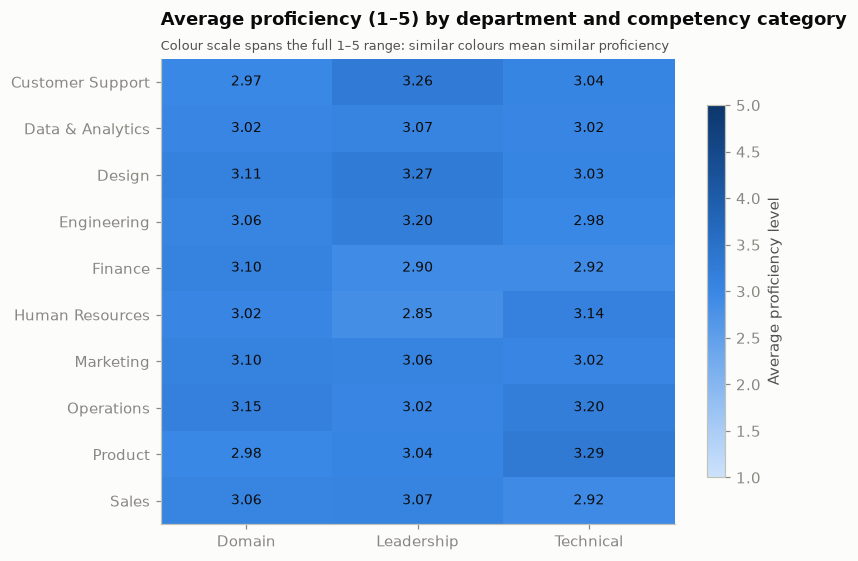

competency_category,Domain,Leadership,Technical,Domain (assessments),Leadership (assessments),Technical (assessments)
department,,,,,,
Customer Support,2.97,3.26,3.04,229,69,120
Data & Analytics,3.02,3.07,3.02,289,90,169
Design,3.11,3.27,3.03,192,67,117
Engineering,3.06,3.20,2.98,152,40,104
Finance,3.10,2.90,2.92,94,30,62
Human Resources,3.02,2.85,3.14,354,92,208
Marketing,3.10,3.06,3.02,121,32,91
Operations,3.15,3.02,3.20,191,57,126
Product,2.98,3.04,3.29,209,74,139


In [18]:
dist = gold("skill_distribution")
weighted = dist.assign(points=dist["proficiency_level"] * dist["employees"])
heat = (weighted.groupby(["department", "competency_category"])[["points", "employees"]].sum()
        .eval("avg = points / employees")["avg"].unstack("competency_category"))
counts = weighted.groupby(["department", "competency_category"])["employees"].sum().unstack("competency_category")

fig, ax = plt.subplots(figsize=(7.5, 5.2))
cmap = mpl.colors.LinearSegmentedColormap.from_list("blue", SEQUENTIAL)
image = ax.imshow(heat.values, cmap=cmap, vmin=1, vmax=5, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns); ax.set_yticks(range(heat.shape[0]), heat.index)
ax.grid(False)
for (i, j), value in pd.DataFrame(heat.values).stack().items():
    ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9, color=SURFACE if value >= 3.4 else INK)
ax.set_title("Average proficiency (1–5) by department and competency category", pad=22)
ax.text(0, 1.012, "Colour scale spans the full 1–5 range: similar colours mean similar proficiency", transform=ax.transAxes,
        fontsize=8.5, color=INK_2, va="bottom")
fig.colorbar(image, ax=ax, label="Average proficiency level", shrink=0.8)
fig.tight_layout(); plt.show()

display(heat.round(2).join(counts.add_suffix(" (assessments)")))

In [19]:
levels = dist.groupby(["competency_category", "proficiency_level"])["employees"].sum().unstack("proficiency_level", fill_value=0)
display((levels.div(levels.sum(axis=1), axis=0)).map(pct).rename_axis(index="category", columns="proficiency level"))

ranked = summary.sort_values("avg_proficiency")
display(pd.concat([ranked.head(5).assign(position="lowest average proficiency"),
                   ranked.tail(5).iloc[::-1].assign(position="highest average proficiency")])
        [["position", "competency_name", "competency_category", "employees_assessed", "avg_proficiency", "avg_required"]]
        .round(2).reset_index(drop=True))

proficiency level,1,2,3,4,5
category,,,,,
Domain,13.0%,20.5%,27.6%,26.4%,12.4%
Leadership,11.8%,20.2%,29.0%,27.3%,11.8%
Technical,12.4%,20.9%,27.8%,25.4%,13.6%


,position,competency_name,competency_category,employees_assessed,avg_proficiency,avg_required
0,lowest average proficiency,Stakeholder Management,Domain,92,2.62,2.84
1,lowest average proficiency,Negotiation,Domain,103,2.80,2.98
2,lowest average proficiency,Risk Management,Domain,94,2.87,3.00
3,lowest average proficiency,DevOps Practices,Technical,86,2.88,2.87
4,lowest average proficiency,Market Analysis,Domain,99,2.91,2.85
5,highest average proficiency,Regulatory Compliance,Domain,86,3.31,3.21
6,highest average proficiency,Localization,Domain,109,3.27,3.08
7,highest average proficiency,Cloud Architecture,Technical,102,3.20,3.11
8,highest average proficiency,Pricing Strategy,Domain,95,3.19,3.16
9,highest average proficiency,Data Privacy,Domain,100,3.18,2.99


**Interpretation**
- **Skills are fairly evenly spread.** Every department × category average lies between 2.85 and 3.29 on the 1–5 scale. No department is far ahead or behind; the lowest cells are Leadership in Human Resources (2.85) and Finance (2.90).
- **Within each category, employees spread across all five levels.** Level 3 is the most common.
- **The real differences are between competencies.** The lowest-scoring competencies, together with the critical-gap ranking in Section 2, mark where organisation-wide upskilling would pay off most.

**Assumptions and limitations**
- **Each employee is assessed on only 2 of 40 competencies.** The distribution is a sample (about 100 assessments per competency), not a full skills inventory, and some department × category cells rest on a few dozen assessments (see the counts above).
- **Proficiency is a self-contained 1–5 scale.** It is compared with the role's required level only in Section 2.

## 8. Summary, assumptions and limitations

| # | Question | Short answer (as of the snapshot above) | Confidence |
|---|---|---|---|
| 1 | Performance ratings and review history | Ratings centre on 3–4. 721 employees improving, 692 stable, 191 declining. Full history per employee in `performance_history`. | High, but only two periods |
| 2 | Critical skill gaps in key competencies | 682 critical gaps (17%), listed by employee and competency. Rates vary by competency (about 10–27%), not by category. | High for the assessed sample; "key" undefined |
| 3 | High-potential employees ready for promotion | 148 employees under the proposed rule. 61 of them have a critical skill gap. | Rule is a proposal (A19) |
| 4 | Training completed by each employee | 2,824 distinct completions and 1,465 certifications. 1,458 employees completed at least one course. | High for counts; no funnel rates |
| 5 | Attrition risk from performance trends | 191 declining employees. Heuristic High band: 193 employees. | Heuristic, not validated (A20) |
| 6 | Performance vs team and project outcomes | Weak, not significant: r ≈ 0.14 over 27 teams | Low (small sample, team-level only) |
| 7 | Distribution of skills | Even across departments and categories (about 3/5). Differences sit at competency level. | Medium (sampled assessments) |

**Decisions and assumptions behind these numbers.** Full list in `docs/business_definitions.md` and `docs/gold_design.md`.
- **Approved:**
  - **A1:** critical gap = missing at least half of the required level.
  - **A13:** an explicit completion counts; sequence checks are informational only.
- **Proposed, awaiting review:**
  - **A4–A7:** pre-hire treatment. Pre-hire reviews are excluded from ratings; pre-hire learning is excluded; pre-hire assessments and talent reviews are included.
  - **A19:** the promotion rule.
  - **A20:** the attrition heuristic.
  - **A21:** the 12-month learning window.
  - **A22:** "as of" = the source snapshot date.
  - **A23:** no funnel rates.
  - **A24:** high/low performer thresholds.

**Data limitations to raise with the data owner**
- **Many HR records are dated before the employee's hire date:** 666 reviews, 234 assessments, 270 talent reviews and 5,161 learning events.
- **Learning events show no reliable sequence.**
- **There is no record of actual leavers**, so attrition risk cannot be validated.
- **Projects are linked to teams only.**
- **There is no course-to-competency mapping.**

In [20]:
# Narrative check: every figure quoted in the text above must match the published Gold data.
# If the data changes, this cell fails, so stale prose is never shipped alongside new numbers.
quoted = {
    "employees with a valid review": (len(rated), 1730),
    "high performers (4-5)": (int(perf["is_high_performer"].sum()), 879),
    "low performers (1-2)": (int(perf["is_low_performer"].sum()), 402),
    "employees with a trend": (int((perf["rating_trend"] != "insufficient_history").sum()), 1604),
    "improving / stable / declining": (tuple(trend_dist.iloc[:3].astype(int)), (721, 692, 191)),
    "pre-hire reviews": (int(history["is_pre_hire"].sum()), 666),
    "critical gaps": (len(critical), 682),
    "High & Ready Now": (int(ready_now.sum()), 357),
    "promotion-ready": (len(ready), 148),
    "ready without a valid rating": (no_rating, 45),
    "ready with a critical gap": (int((ready["critical_gap_count"] > 0).sum()), 61),
    "distinct completions": (int(learning["courses_completed"].sum()), 2824),
    "certifications": (int(learning["certifications_earned"].sum()), 1465),
    "employees with a completion": (int((learning["courses_completed"] > 0).sum()), 1458),
    "inactive 12 months": (int((~learning["is_learning_active_12m"]).sum()), 56),
    "pre-hire learning events excluded": (int(learning["pre_hire_events_excluded"].sum()), 5161),
    "declining trend": (len(declining), 191),
    "declining and HR High": (int((declining["hr_attrition_risk"] == "High").sum()), 116),
    "High / Medium risk band": ((int(bands["High"]), int(bands["Medium"])), (193, 271)),
    "teams with projects": (n, 27),
    "correlation r (2 dp)": (round(r, 2), 0.14),
    "employees with a critical gap / with two": ((len(per_employee), int((per_employee["critical_gaps"] >= 2).sum())), (633, 49)),
    "competency critical-gap rate min / max (%)": ((round(summary["critical_gap_rate"].min() * 100, 1),
                                                    round(summary["critical_gap_rate"].max() * 100, 1)), (10.4, 27.2)),
    "highest critical-gap competency": (top["competency_name"].iloc[0], "Stakeholder Management"),
    "category rates Domain / Technical / Leadership (%)": (tuple(round(by_category.loc[c, "critical_gap_rate"] * 100, 1)
                                                             for c in ("Domain", "Technical", "Leadership")), (17.5, 16.6, 16.3)),
    "High & Ready Now failing on rating / no rating": ((int(ready_now.sum()) - len(ready) - no_rating, no_rating), (164, 45)),
    "employees with 0 / 1 / 2 completions": (tuple(int(completed.get(k, 0)) for k in (0, 1, 2)), (542, 652, 434)),
    "High band with declining trend": (int(((risk["risk_band"] == "High") & risk["is_rating_declining"]).sum()), 161),
    "on-time vs none-on-time team rating": ((round(on_time.groupby("delivery")["avg_latest_valid_rating"].mean()["all on time"], 2),
                                             round(on_time.groupby("delivery")["avg_latest_valid_rating"].mean()["none on time"], 2)),
                                            (3.58, 3.22)),
    "department x category average min / max": ((round(heat.min().min(), 2), round(heat.max().max(), 2)), (2.85, 3.29)),
}
stale = {k: v for k, v in quoted.items() if v[0] != v[1]}
assert not stale, f"Narrative is out of date for: {stale}"
print(f"All {len(quoted)} figures quoted in the narrative match the published Gold data (as of {gold_pointer.as_of}).")

All 30 figures quoted in the narrative match the published Gold data (as of 2026-10-15).
